In [67]:
import random
import numpy as np 
import matplotlib.pyplot as plt
from datetime import datetime, timezone
import dukascopy_python.compat as duka
from dukascopy_python.compat.instruments import (
    INSTRUMENT_FX_MAJORS_EUR_USD,
)

In [ ]:
nwalks = 1000
nsteps = 250
rng = np.random.default_rng(42)
draw = rng.integers(0,2,size = (nwalks,nsteps))
step = np.where(draw > 0, 1,-1)
walks = step.cumsum(axis = 1)


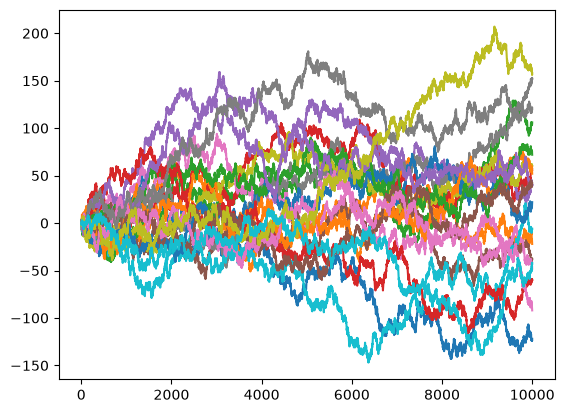

In [74]:
plt.plot(walks[:20].T)
plt.show()

In [ ]:
cross_over = (np.abs(walks[:,-1:]) > 15.8).any(axis = 1).mean()
print(cross_over)


0.332
4


In [63]:
def ma_loop(w):
    ma20_loop = []
    for i in range(19, len(w)):
        avg = np.mean(w[i-19:i+1])
        ma20_loop.append(avg)
    ma20_loop = np.array(ma20_loop)
    return ma20_loop

In [ ]:
w = walks[0]
cs = np.cumsum(w)

ma20 = np.empty(len(w) - 19)

ma20[0] = cs[19] / 20
ma20[1:] = (cs[20:] - cs[:-20]) / 20

In [64]:
print(type(ma_loop(w)))   # dự đoán: ?

<class 'numpy.ndarray'>


In [43]:
r = np.diff(walks, axis=1) * 0.01
signal = np.where(r > 0,1,-1)
print(signal)
print(r)

[[ 1  1 -1 ... -1  1 -1]
 [-1 -1 -1 ... -1  1 -1]
 [ 1  1  1 ... -1 -1 -1]
 ...
 [ 1  1  1 ... -1  1 -1]
 [-1 -1  1 ... -1 -1  1]
 [ 1  1 -1 ... -1 -1 -1]]
[[ 0.01  0.01 -0.01 ... -0.01  0.01 -0.01]
 [-0.01 -0.01 -0.01 ... -0.01  0.01 -0.01]
 [ 0.01  0.01  0.01 ... -0.01 -0.01 -0.01]
 ...
 [ 0.01  0.01  0.01 ... -0.01  0.01 -0.01]
 [-0.01 -0.01  0.01 ... -0.01 -0.01  0.01]
 [ 0.01  0.01 -0.01 ... -0.01 -0.01 -0.01]]


In [ ]:
strat_ret = r[:, 1:] * signal[:,:-1]
pnl = np.prod(strat_ret + 1, axis = 1) - 1

(array([839]),)


In [62]:
print((pnl >= 0.2).sum(), (pnl >= 0.2).mean())

99 0.099


In [66]:
assert np.allclose(ma20, ma_loop(w))

In [70]:
df = duka.fetch(
    INSTRUMENT_FX_MAJORS_EUR_USD,
    duka.INTERVAL_HOUR_1,
    duka.OFFER_SIDE_BID,
    datetime(2025, 1, 1, tzinfo=timezone.utc),
    datetime(2026, 1, 1, tzinfo=timezone.utc),
)
df.to_csv("../data/raw/EURUSD_H1.csv")

In [ ]:
print(len(df))     # dự đoán: 6225 (gợi ý: FX giao dịch 24 giờ × 5 ngày/tuần × 52 tuần, trừ lễ)
print(df.head())   # dự đoán: có 6 dòng, theo giờ UTC+0

6225
                              open     high      low    close   volume
timestamp                                                             
2025-01-01 22:00:00+00:00  1.03503  1.03577  1.03483  1.03550  1443.22
2025-01-01 23:00:00+00:00  1.03550  1.03563  1.03462  1.03507  4447.37
2025-01-02 00:00:00+00:00  1.03508  1.03564  1.03472  1.03520  3681.37
2025-01-02 01:00:00+00:00  1.03521  1.03606  1.03442  1.03578  5012.45
2025-01-02 02:00:00+00:00  1.03577  1.03712  1.03577  1.03709  2791.47
